# Credit Card Fraud Detection Model

The goal is to create a model to detect fraudulent credit card transactions. The model is built based on an kaggle dataset. \
Link to the data: https://www.kaggle.com/datasets/neharoychoudhury/credit-card-fraud-data

In [1]:
# data manipulation
import pandas as pd
import numpy as np

# visualization
import matplotlib as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../fraud_data.csv')

In [3]:
print(df.head())

  trans_date_trans_time                          merchant        category  \
0      04-01-2019 00:58  "Stokes, Christiansen and Sipes"     grocery_net   
1      04-01-2019 15:06                      Predovic Inc    shopping_net   
2      04-01-2019 22:37                   Wisozk and Sons        misc_pos   
3      04-01-2019 23:06                    Murray-Smitham     grocery_pos   
4      04-01-2019 23:59                        Friesen Lt  health_fitness   

      amt   city state      lat      long  city_pop  \
0   14.37  Wales    AK  64.7556 -165.6723       145   
1  966.11  Wales    AK  64.7556 -165.6723       145   
2   49.61  Wales    AK  64.7556 -165.6723       145   
3  295.26  Wales    AK  64.7556 -165.6723       145   
4   18.17  Wales    AK  64.7556 -165.6723       145   

                          job         dob                         trans_num  \
0  "Administrator, education"  09-11-1939  a3806e984cec6ac0096d8184c64ad3a1   
1  "Administrator, education"  09-11-1939  a5918

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14446 entries, 0 to 14445
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   trans_date_trans_time  14446 non-null  str    
 1   merchant               14446 non-null  str    
 2   category               14446 non-null  str    
 3   amt                    14446 non-null  float64
 4   city                   14446 non-null  str    
 5   state                  14446 non-null  str    
 6   lat                    14446 non-null  float64
 7   long                   14446 non-null  float64
 8   city_pop               14446 non-null  int64  
 9   job                    14446 non-null  str    
 10  dob                    14446 non-null  str    
 11  trans_num              14446 non-null  str    
 12  merch_lat              14446 non-null  float64
 13  merch_long             14446 non-null  float64
 14  is_fraud               14446 non-null  str    
dtypes: float64(5)

## First Observation
There are no missing values in the dataset

# EDA (Univariate, Bivariate)

## is_fraud

In [5]:
df.is_fraud.value_counts()

is_fraud
0                         12600
1                          1844
1"2020-12-24 16:56:24"        1
0"2019-01-01 00:00:44"        1
Name: count, dtype: int64

**Observation:**
- There are two values in the is_fraud column that are timestamps -> delete the two rows
- The clumn is object type -> convert to int

In [6]:
# get index of the two defect rows
df.loc[~(df.is_fraud.isin(['0','1']))]

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
1781,11-12-2020 23:19,Thompson-Gleason,health_fitness,19.45,Lakeport,CA,39.0470,-122.9328,11256,Podiatrist,18-10-1972,bfde75d978bb9905a4a8c87440692a4c,39.251880,-122.490946,"1""2020-12-24 16:56:24"""
7780,31-12-2020 23:59,Breitenberg LLC,travel,7.99,Mesa,ID,44.6255,-116.4493,129,Cartographer,15-12-1965,14392d723bb7737606b2700ac791b7aa,44.470525,-117.080888,"0""2019-01-01 00:00:44"""


In [7]:
# drop the rows
df = df.drop(index=[1781,7780])
# convert the column to int 
df['is_fraud'] = df.is_fraud.astype('int')

**Conclusion:** \
There are  ~14.5% fraudulent transactions in the dataset

## merchant

In [8]:
# Check fraud rate for different merchants
merchant_fraud_rate = df.groupby('merchant')['is_fraud'].agg(['count', 'sum', 'mean']).sort_values(by='mean', ascending=False)
merchant_fraud_rate[:10]

,count,sum,mean
merchant,,,
Brown PLC,10,6,0.600000
Rempel Inc,23,12,0.521739
Kunze Inc,31,16,0.516129
Kerluke-Abshire,35,18,0.514286
Emmerich-Luettgen,4,2,0.500000
"""Romaguera, Cruickshank and Greenholt""",37,18,0.486486
Kiehn-Emmerich,42,20,0.476190
"""Moore, Dibbert and Koepp""",17,8,0.470588
Terry-Huel,30,14,0.466667


**Observation:**\
There are merchants with very high fraud rate but this could be due to random variation. \
**Next** \
To confirm signal -> check distribution for merchant counts and plot count against fraud_rate.

In [9]:
df.merchant.value_counts().describe()

count    693.000000
mean      20.842713
std        8.566288
min        3.000000
25%       15.000000
50%       20.000000
75%       26.000000
max       58.000000
Name: count, dtype: float64

<Axes: xlabel='count', ylabel='mean'>

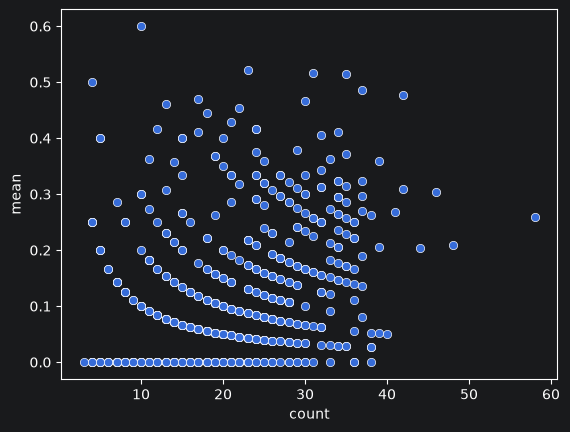

In [10]:
sns.scatterplot(data=merchant_fraud_rate, x='count', y='mean')

Most merchants occure about twenty times -> signal possibly noisy

**Next:** Test if variation of fraud rates is random or real signal 

In [11]:
# calculate the variation of the fraud rates across the merchants
real_std = df.groupby('merchant')['is_fraud'].mean().std()
print(f"Real STD: {round(real_std,2)}")


Real STD: 0.12


Shuffle the fraud variable to break every signal that may exists between merchant and fraud. Make multiple simulations then compare the mean random std of the samples to the real std.

In [12]:
simulated_stds = []

for _ in range(1000):
    shuffled = np.random.permutation(df['is_fraud'])

    std = df.assign(shuffled=shuffled).groupby('merchant')['shuffled'].mean().std()

    simulated_stds.append(std)

print(f"Real STD: {round(real_std,2)}")
print(f"Mean random STD: {round(np.mean(simulated_stds),2)}")
print(f"Max random STD: {round(np.max(simulated_stds),2)}")

Real STD: 0.12
Mean random STD: 0.08
Max random STD: 0.09


**Conclusion:** \
Since the real std is is higher than all the simulated stds it is very likely that merchant is a useful feature. However not every merchant will be reliable due to low counts per merchants. \
**Decision:**\
Use feature in the model but use feature encoding with smoothing to balance out high fraud rate variance in small sample merchants.

## category

In [13]:
df.category.value_counts()

category
grocery_pos       1602
gas_transport     1430
shopping_net      1408
shopping_pos      1354
home              1304
kids_pets         1141
personal_care      990
entertainment      953
health_fitness     890
food_dining        870
misc_pos           823
misc_net           821
grocery_net        474
travel             384
Name: count, dtype: int64

In [14]:
# get fraud rate per category
category_fraudrate = df.groupby('category')['is_fraud'].agg(['count','sum','mean']).sort_values('mean', ascending=False)
category_fraudrate

,count,sum,mean
category,,,
shopping_net,1408,396,0.281250
grocery_pos,1602,444,0.277154
misc_net,821,223,0.271620
shopping_pos,1354,194,0.143279
gas_transport,1430,159,0.111189
travel,384,34,0.088542
misc_pos,823,64,0.077764
grocery_net,474,32,0.067511
entertainment,953,59,0.061910


**Conclusion:**\
Clear stable feature here. Use for model with One-Hot-Encoding